# Construcción del dataset: ENNI + Common Voice

Este notebook analiza los dos corpus de `datasets/` y los une en un único dataset con las
clases del proyecto (`nino` ≤ 12, `adolescente` 13–17, `adulto` ≥ 18):

| Corpus | Carpeta | Aporta | Etiquetas |
|---|---|---|---|
| **ENNI child speech synthesis** | `datasets/enni-child-speech-synthesis/` | `nino` (4–10 años) | edad exacta, género, hablante, trastorno del habla |
| **Common Voice (Kaggle, 2017)** | `datasets/archive/` | `adolescente` y `adulto` | década de edad autodeclarada, género, acento |

Salida: `datasets/merged/` con los audios normalizados (WAV 16 kHz mono) y un `metadata.csv`
con la partición train/val/test **por hablante**.

> ⚠️ Recordatorio: el modelo que se entrene con esto es solo un **estimador de riesgo** basado en la
> edad aparente de la voz, nunca un decisor. Ver `CLAUDE.md`.

## 1. Configuración

In [1]:
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import librosa
from joblib import Parallel, delayed
from tqdm.auto import tqdm

from grooming_risk.config import CLASSES, SAMPLE_RATE, MIN_SEGMENT_SEC, age_to_class
from grooming_risk.datasets import CV_AGE

DATASETS_DIR = ROOT / "datasets"
ENNI_DIR = DATASETS_DIR / "enni-child-speech-synthesis"
CV_DIR = DATASETS_DIR / "archive"
OUT_DIR = DATASETS_DIR / "merged"

SEED = 0
MAX_SEC = 15.0               # se descartan clips muy largos (casi no hay)
MAX_PER_GROUP = 400          # tope de clips por (pseudo)hablante de Common Voice
ADULT_TARGET = None          # None = igualar a la clase menor más numerosa
SPLIT_FRACS = {"test": 0.15, "val": 0.15}  # el resto va a train
EXPORT_AUDIO = True          # escribe los WAV 16 kHz en datasets/merged/audio/
N_JOBS = -1

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(SEED)

## 2. ENNI child speech synthesis

Habla infantil en inglés (4–10 años) **sintetizada** a partir del corpus TalkBank FASA ENNI
(niños con desarrollo típico `td` y con trastorno específico del lenguaje `sli`).

### 2.1 Descarga y etiquetas

Se descargan del repositorio de Hugging Face los WAV originales y `metadata.json` (sin la librería
`datasets`, que desde la v4 no ejecuta el script de carga del repo e ignora las etiquetas).
En `metadata.json` cada etiqueta viene como respuesta en lenguaje natural (pregunta/respuesta);
de ahí se extraen edad, género, transcripción y trastorno del habla a `metadata.csv`.
Si los audios ya están en `datasets/enni-child-speech-synthesis/` no se descarga nada.

In [2]:
import re, shutil
from huggingface_hub import hf_hub_download, snapshot_download

ENNI_REPO = "jsun39/enni-child-speech-synthesis"

if not any(ENNI_DIR.glob("*.wav")):
    tmp = ENNI_DIR / "_descarga"
    snapshot_download(ENNI_REPO, repo_type="dataset", local_dir=tmp, allow_patterns=["audio/*.wav"])
    for wav in (tmp / "audio").glob("*.wav"):
        wav.rename(ENNI_DIR / wav.name)
    shutil.rmtree(tmp)

def parse_labels(item):
    turns = item["conversation"]
    row = {"file": item["audio_file"]}
    for q, a in zip(turns[::2], turns[1::2]):
        q, a = q["value"].lower(), a["value"]
        if re.search(r"\bages?\b|how old|years", q):
            row["age"] = int(re.search(r"\d+", a).group())
        elif re.search(r"\bgender\b|\bsex\b", q):
            row["gender"] = "F" if re.search(r"female|girl", a, re.I) else "M"
        elif re.search(r"disorder|impair|typical|normal", q):
            row["disordered"] = not re.search(r"\bno\b|\bnot\b|free from|typical|normal", a, re.I)
        elif re.search(r"transcri|writ|text|word|said|say", q):
            row["transcription"] = re.sub(r"^This is the english transcription,\s*", "", a)
    # original_path: .../out/<speaker_id>/<td|sli>-<inicio>_<fin>-<n>.wav
    parts = Path(item["original_path"]).parts
    row["speaker_id"] = parts[-2]
    row["group"] = parts[-1].split("-")[0]  # td = desarrollo típico, sli = trastorno del lenguaje
    row["original_path"] = item["original_path"]
    return row

if not (ENNI_DIR / "metadata.csv").exists():
    metadata = json.loads(Path(hf_hub_download(ENNI_REPO, "metadata.json", repo_type="dataset")).read_text())
    labels = pd.DataFrame(map(parse_labels, metadata))
    labels = labels[labels["file"].map(lambda f: (ENNI_DIR / f).exists())]  # solo audios presentes
    labels.to_csv(ENNI_DIR / "metadata.csv", index=False)
print(len(list(ENNI_DIR.glob("*.wav"))), "audios ·", ENNI_DIR / "metadata.csv")

9997 audios · /Users/davidcervantes/Documents/Reconocimiento de Voz/riesgo-grooming-audio/datasets/enni-child-speech-synthesis/metadata.csv


### 2.2 Análisis

In [3]:
enni = pd.read_csv(ENNI_DIR / "metadata.csv", dtype={"speaker_id": str})
enni["path"] = enni["file"].map(lambda f: str(ENNI_DIR / f))
assert enni["path"].map(lambda p: Path(p).exists()).all(), "Faltan audios de ENNI"

# El género se pregunta solo en ~80 % de los clips, pero cada hablante tiene un único
# género, así que se completa a partir de sus otros clips.
spk_gender = enni.dropna(subset=["gender"]).groupby("speaker_id")["gender"].first()
enni["gender"] = enni["gender"].fillna(enni["speaker_id"].map(spk_gender))
enni["gender"] = enni["gender"].map({"M": "male", "F": "female"})

info = [sf.info(p) for p in enni["path"]]
enni["duration"] = [i.duration for i in info]
enni["orig_sr"] = [i.samplerate for i in info]

print(f"{len(enni)} clips · {enni.speaker_id.nunique()} hablantes")
print("Frecuencia de muestreo:", enni.orig_sr.value_counts().to_dict())
print("Género (tras completar):", enni.gender.value_counts(dropna=False).to_dict())
print("Grupo:", enni.group.value_counts().to_dict())
enni.head()

9997 clips · 349 hablantes
Frecuencia de muestreo: {24000: 9997}
Género (tras completar): {'female': 5040, 'male': 4957}
Grupo: {'td': 8332, 'sli': 1665}


,file,transcription,age,gender,disordered,speaker_id,group,original_path,path,duration,orig_sr
0,audio_000000.wav,he want the toy.,9,male,True,7217495525878529934,sli,speech_synthesis/seed-1/FASA_ENNI/out/72174955...,/Users/davidcervantes/Documents/Reconocimiento...,2.08,24000
1,audio_000001.wav,the girl takes the ball this morning.,9,male,False,8950097825990578905,td,speech_synthesis/seed-1/FASA_ENNI/out/89500978...,/Users/davidcervantes/Documents/Reconocimiento...,3.16,24000
2,audio_000002.wav,the girl watched the waves while her mother co...,8,male,False,6914828268323111879,td,speech_synthesis/seed-1/FASA_ENNI/out/69148282...,/Users/davidcervantes/Documents/Reconocimiento...,6.52,24000
3,audio_000003.wav,she wants the apple.,10,female,False,7687928770013676450,td,speech_synthesis/seed-1/FASA_ENNI/out/76879287...,/Users/davidcervantes/Documents/Reconocimiento...,3.04,24000
4,audio_000004.wav,him run the book.,9,male,True,7217495525878529934,sli,speech_synthesis/seed-1/FASA_ENNI/out/72174955...,/Users/davidcervantes/Documents/Reconocimiento...,4.80,24000


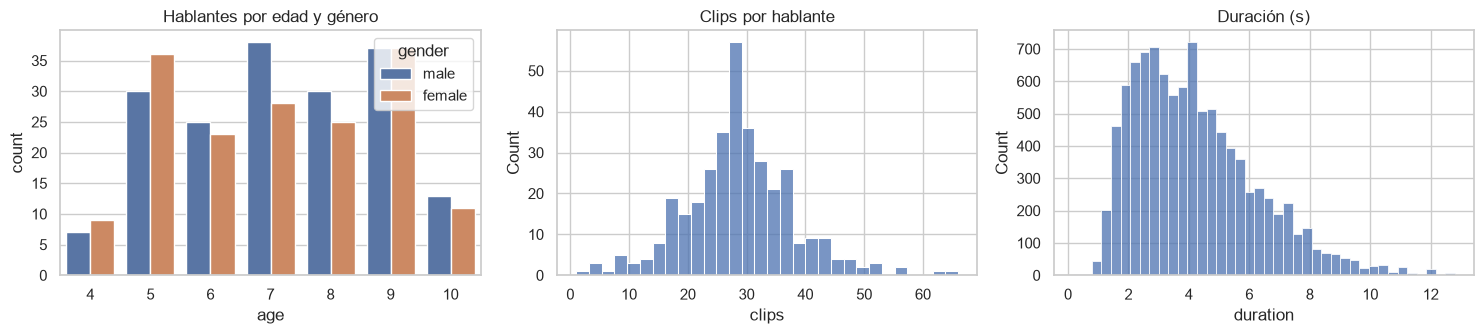

,age,clips
count,349.00000,349.000000
mean,7.13467,28.644699
std,1.70923,9.285686
min,4.00000,1.000000
25%,6.00000,24.000000
50%,7.00000,28.000000
75%,9.00000,34.000000
max,10.00000,66.000000


In [4]:
spk = enni.groupby("speaker_id").agg(age=("age", "first"), gender=("gender", "first"),
                                     group=("group", "first"), clips=("file", "size"))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.countplot(data=spk, x="age", hue="gender", ax=ax[0]).set_title("Hablantes por edad y género")
sns.histplot(spk["clips"], bins=30, ax=ax[1]).set_title("Clips por hablante")
sns.histplot(enni["duration"], bins=40, ax=ax[2]).set_title("Duración (s)")
plt.tight_layout(); plt.show()
spk.describe()

**Observaciones ENNI**

- Todos los hablantes tienen entre 4 y 10 años → todo el corpus es clase `nino`.
- Cada hablante tiene una sola edad y un solo género (comprobado al extraer las etiquetas).
- Es habla **sintetizada**: las voces imitan a niños reales pero el canal es "de laboratorio"
  (WAV 24 kHz sin ruido). Esto es un riesgo de *atajo*: el modelo podría aprender
  "audio limpio sintético = niño" en lugar de rasgos de edad. Se audita en la sección 6.
- Los niños `sli` se mantienen: su voz sigue siendo infantil; queda la columna `disordered`
  por si se quiere filtrar o estratificar.

## 3. Common Voice (versión Kaggle)

Habla leída en inglés grabada por voluntarios con su propio micrófono (MP3 48 kHz).
Las subcarpetas `valid`/`other` indican si la transcripción fue validada; para estimar edad
eso no importa, así que se usan ambas. `invalid` se descarta (muchos clips vacíos o con ruido).

In [5]:
frames = []
for csv in sorted(CV_DIR.glob("cv-*.csv")):
    subset = csv.stem
    d = pd.read_csv(csv)
    d["subset"] = subset
    d["path"] = d["filename"].map(lambda f: str(CV_DIR / subset / f))
    frames.append(d)
cv_all = pd.concat(frames, ignore_index=True)

resumen = (cv_all.assign(con_edad=cv_all["age"].notna())
                 .groupby("subset").agg(clips=("path", "size"), con_edad=("con_edad", "sum")))
resumen["%_con_edad"] = (100 * resumen["con_edad"] / resumen["clips"]).round(1)
resumen

,clips,con_edad,%_con_edad
subset,,,
cv-invalid,25403,5851,23.0
cv-other-dev,3022,1347,44.6
cv-other-test,2961,1283,43.3
cv-other-train,145135,63702,43.9
cv-valid-dev,4076,1528,37.5
cv-valid-test,3995,1542,38.6
cv-valid-train,195776,73768,37.7


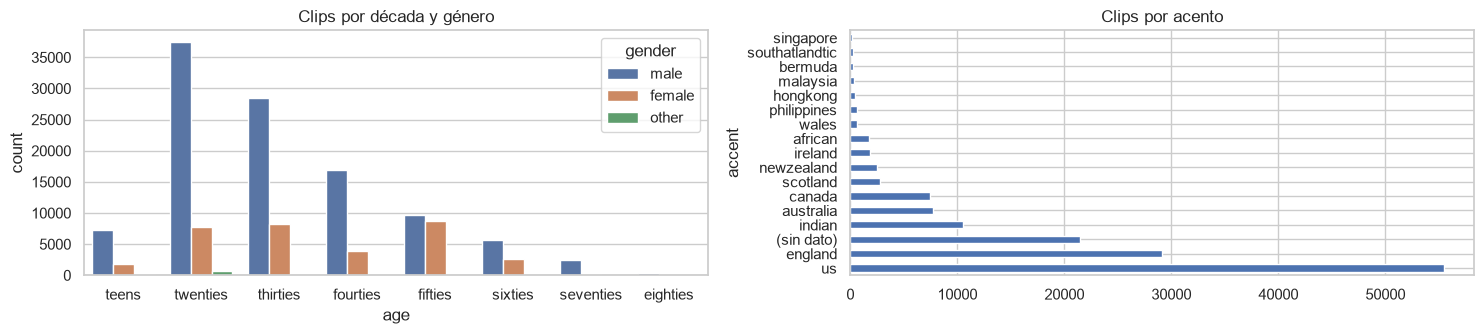

143170 clips con edad (valid + other)


In [6]:
cv = cv_all[(cv_all["subset"] != "cv-invalid") & cv_all["age"].notna()].copy()
cv = cv[cv["age"].isin(CV_AGE)]
age_order = [a for a in CV_AGE if a in set(cv["age"])]

fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))
sns.countplot(data=cv, x="age", hue="gender", order=age_order, ax=ax[0]).set_title("Clips por década y género")
cv["accent"].fillna("(sin dato)").value_counts().plot.barh(ax=ax[1], title="Clips por acento")
plt.tight_layout(); plt.show()
print(f"{len(cv)} clips con edad (valid + other)")

### Sin identificador de hablante → pseudo-hablante demográfico

Esta versión de Common Voice **no trae `client_id`**, así que no se sabe qué clips son de la misma
persona. Para que ningún hablante quede repartido entre train y test se agrupan los clips por
**(década, género, acento)**: un mismo voluntario siempre declara los mismos datos, así que todos
sus clips caen en el mismo grupo. Es una agrupación conservadora (cada grupo junta a muchas
personas), lo que hace la partición más estricta, no más permisiva.

Para que un grupo enorme (p.ej. `twenties|male|us`) no domine, se limita a `MAX_PER_GROUP` clips.

In [7]:
cv["gender"] = cv["gender"].where(cv["gender"].isin(["male", "female"]))  # "other" es muy escaso
cv["speaker_id"] = ("cv:" + cv["age"] + "|" + cv["gender"].fillna("na") + "|"
                    + cv["accent"].fillna("na"))
cv["age_num"] = cv["age"].map(CV_AGE)
cv["age_class"] = cv["age_num"].map(age_to_class)

grupos = cv.groupby(["age_class", "speaker_id"]).size().rename("clips").reset_index()
grupos.groupby("age_class")["clips"].describe()

,count,mean,std,min,25%,50%,75%,max
age_class,,,,,,,,
adolescente,25.0,371.120000,697.825033,13.0,50.00,124.0,233.0,3118.0
adulto,152.0,880.868421,2008.708862,1.0,45.25,181.0,674.5,15226.0


## 4. Mapeo a las clases del proyecto

| Clase | Fuente | Edad usada | Comentario |
|---|---|---|---|
| `nino` | ENNI | exacta (4–10) | habla sintetizada |
| `adolescente` | Common Voice `teens` | 16 (centro aprox.) | **ruidosa**: CV define `teens` como "< 19", incluye 18–19 y posibles < 13 |
| `adulto` | Common Voice `twenties`+ | centro de la década | muy abundante → se submuestrea |

El código de clase es el mismo que en `grooming_risk/config.py` (`age_to_class`).

In [8]:
enni_df = pd.DataFrame({
    "path": enni["path"], "speaker_id": "enni:" + enni["speaker_id"], "age": enni["age"].astype(float),
    "age_class": enni["age"].map(age_to_class), "gender": enni["gender"], "accent": "na",
    "source": "enni", "subset": enni["group"], "text": enni["transcription"],
    "disordered": enni["disordered"], "duration": enni["duration"], "orig_sr": enni["orig_sr"],
})
cv_df = pd.DataFrame({
    "path": cv["path"], "speaker_id": cv["speaker_id"], "age": cv["age_num"].astype(float),
    "age_class": cv["age_class"], "gender": cv["gender"], "accent": cv["accent"].fillna("na"),
    "source": "common_voice", "subset": cv["subset"], "text": cv["text"],
    "disordered": False, "duration": np.nan, "orig_sr": np.nan,
})
pd.concat([enni_df, cv_df]).groupby(["age_class", "source"]).agg(
    clips=("path", "size"), grupos_hablante=("speaker_id", "nunique")).loc[CLASSES]

,,clips,grupos_hablante
age_class,source,,
nino,enni,9997,349
adolescente,common_voice,9278,25
adulto,common_voice,133892,152


## 5. Selección y balanceo

1. Tope de `MAX_PER_GROUP` clips por pseudo-hablante de Common Voice (más diversidad de grupos).
2. `adulto` se submuestrea hasta `ADULT_TARGET` repartiendo por igual entre grupos demográficos.
3. Se miden duraciones y se descartan clips < `MIN_SEGMENT_SEC` o > `MAX_SEC`.

In [9]:
def cap_per_group(df, cap, seed=SEED):
    return (df.sample(frac=1, random_state=seed).groupby("speaker_id").head(cap))

def sample_balanced_groups(df, n, seed=SEED):
    """Toma n clips repartidos lo más uniformemente posible entre speaker_id."""
    if len(df) <= n:
        return df
    df = df.sample(frac=1, random_state=seed)
    df["_rank"] = df.groupby("speaker_id").cumcount()
    return df.sort_values(["_rank", "speaker_id"]).head(n).drop(columns="_rank")

teens = cap_per_group(cv_df[cv_df["age_class"] == "adolescente"], MAX_PER_GROUP)
adults = cap_per_group(cv_df[cv_df["age_class"] == "adulto"], MAX_PER_GROUP)
target = ADULT_TARGET or max(len(enni_df), len(teens))
adults = sample_balanced_groups(adults, target)

df = pd.concat([enni_df, teens, adults], ignore_index=True)

# Duración de los MP3 seleccionados (los de ENNI ya se midieron)
falta = df["duration"].isna()
info = Parallel(n_jobs=N_JOBS)(delayed(sf.info)(p) for p in tqdm(df.loc[falta, "path"], desc="sf.info"))
df.loc[falta, "duration"] = [i.duration for i in info]
df.loc[falta, "orig_sr"] = [i.samplerate for i in info]

antes = len(df)
df = df[df["duration"].between(MIN_SEGMENT_SEC, MAX_SEC)].reset_index(drop=True)
print(f"Descartados por duración: {antes - len(df)}")
df.groupby("age_class").agg(clips=("path", "size"), grupos=("speaker_id", "nunique"),
                            horas=("duration", lambda s: round(s.sum() / 3600, 1))).loc[CLASSES]

sf.info:   0%|          | 0/13964 [00:00<?, ?it/s]

Descartados por duración: 55


,clips,grupos,horas
age_class,,,
nino,9970,348,11.6
adolescente,3965,25,4.1
adulto,9971,152,12.0


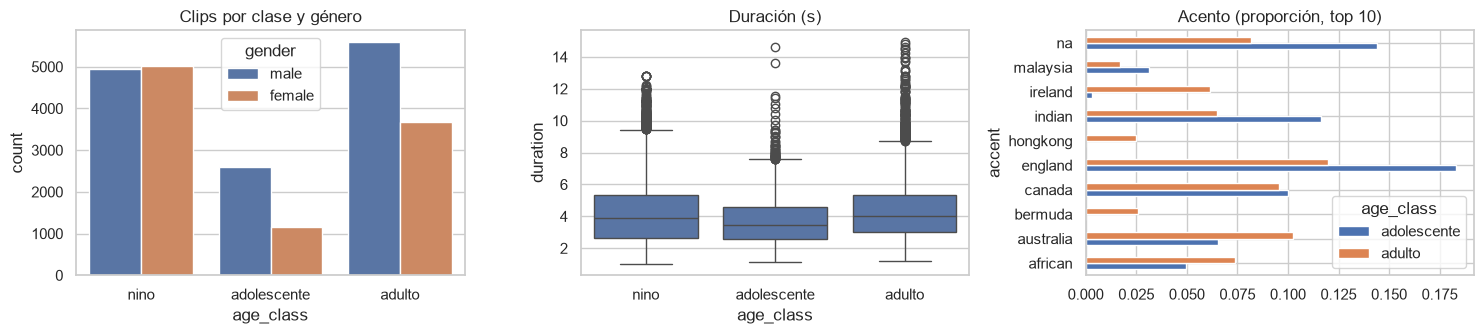

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.countplot(data=df, x="age_class", hue="gender", order=CLASSES, ax=ax[0]).set_title("Clips por clase y género")
sns.boxplot(data=df, x="age_class", y="duration", order=CLASSES, ax=ax[1]).set_title("Duración (s)")
(df[df.source == "common_voice"].groupby("age_class")["accent"].value_counts(normalize=True)
   .unstack(0).loc[:, ["adolescente", "adulto"]].head(10)
   .plot.barh(ax=ax[2], title="Acento (proporción, top 10)"))
plt.tight_layout(); plt.show()

## 6. Auditoría de canal (riesgo de atajo)

Como cada clase viene de un único corpus, el modelo podría separar las clases por el **canal**
(formato, ruido, ancho de banda, nivel) en lugar de por la voz. Se comparan algunos descriptores
de canal ya remuestreados a 16 kHz sobre una muestra por clase. Diferencias grandes aquí son una
señal de alarma a vigilar en la evaluación del modelo (sección 7 del notebook de entrenamiento).

canal:   0%|          | 0/450 [00:00<?, ?it/s]

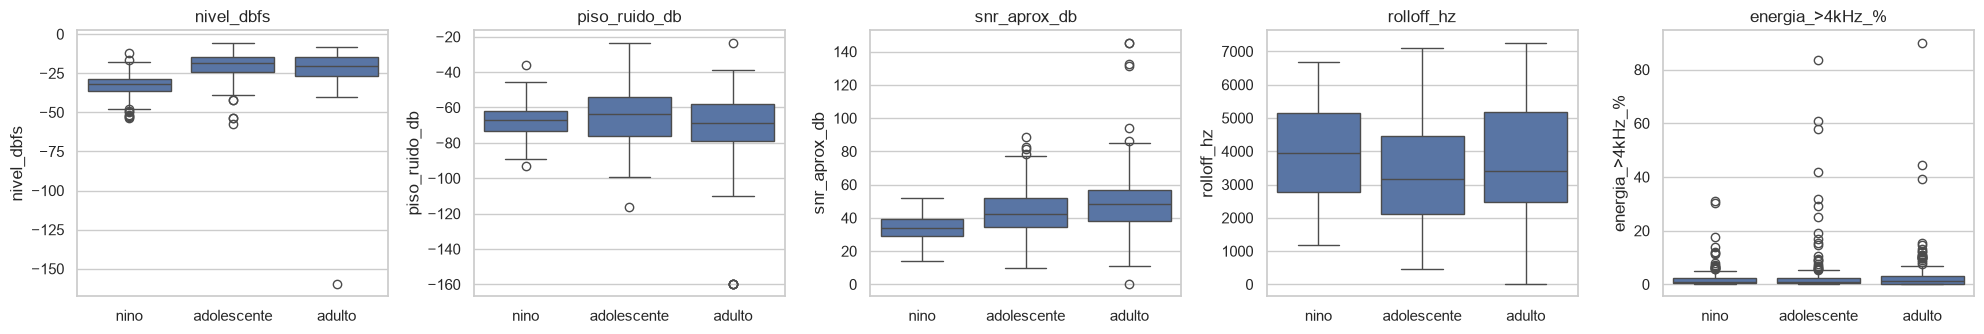

,nivel_dbfs,piso_ruido_db,snr_aprox_db,rolloff_hz,energia_>4kHz_%
age_class,,,,,
nino,-32.0,-66.9,34.1,3953.1,0.8
adolescente,-18.2,-63.5,42.6,3156.2,1.0
adulto,-20.1,-68.8,48.3,3406.2,1.1


In [11]:
def load_16k(path):
    y, sr = sf.read(path, dtype="float32", always_2d=True)
    y = y.mean(axis=1)
    if sr != SAMPLE_RATE:
        y = librosa.resample(y, orig_sr=sr, target_sr=SAMPLE_RATE, res_type="soxr_hq")
    return y

def channel_stats(path):
    y = load_16k(path)
    rms = librosa.feature.rms(y=y)[0]
    db = 20 * np.log10(rms + 1e-8)
    S = np.abs(librosa.stft(y, n_fft=512)) ** 2
    freqs = librosa.fft_frequencies(sr=SAMPLE_RATE, n_fft=512)
    return {
        "nivel_dbfs": float(np.percentile(db, 95)),
        "piso_ruido_db": float(np.percentile(db, 10)),
        "snr_aprox_db": float(np.percentile(db, 95) - np.percentile(db, 10)),
        "rolloff_hz": float(np.median(librosa.feature.spectral_rolloff(S=S, sr=SAMPLE_RATE, roll_percent=0.99))),
        "energia_>4kHz_%": float(100 * S[freqs > 4000].sum() / max(S.sum(), 1e-12)),
    }

muestra = df.sample(frac=1, random_state=SEED).groupby("age_class").head(150)
stats = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(channel_stats)(p) for p in tqdm(muestra["path"], desc="canal")))
stats["age_class"] = muestra["age_class"].to_numpy()

cols = [c for c in stats.columns if c != "age_class"]
fig, ax = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.5))
for a, c in zip(ax, cols):
    sns.boxplot(data=stats, x="age_class", y=c, order=CLASSES, ax=a).set_title(c)
    a.set_xlabel("")
plt.tight_layout(); plt.show()
stats.groupby("age_class")[cols].median().loc[CLASSES].round(1)

**Cómo leerlo:** si `nino` (ENNI) tiene un piso de ruido mucho más bajo o un `rolloff` muy distinto
de las otras clases, el modelo puede usar eso como atajo. Mitigaciones previstas en el proyecto:
la aumentación de canal (`grooming_risk/audio.py`, igual para todas las clases) y, sobre todo,
añadir corpus con niños **y** adultos grabados en el mismo canal (p.ej. speechocean762, ver
`data/README.md`).

## 7. Partición train / val / test por hablante

Dentro de cada clase se reparten **grupos de hablante completos** (hablante real en ENNI,
pseudo-hablante demográfico en Common Voice) hasta alcanzar las proporciones de `SPLIT_FRACS`.
Ningún `speaker_id` aparece en más de un split.

In [12]:
def split_by_speaker(df, fracs, seed=SEED):
    rng = np.random.default_rng(seed)
    split = pd.Series("train", index=df.index)
    for _, g in df.groupby("age_class"):
        sizes = g.groupby("speaker_id").size()
        total, filled = sizes.sum(), {k: 0 for k in fracs}
        for spk in rng.permutation(sizes.index.to_numpy()):
            dest = next((k for k in fracs if filled[k] < fracs[k] * total), "train")
            if dest != "train":
                filled[dest] += sizes[spk]
            split[g.index[g["speaker_id"] == spk]] = dest
    return split

df["split"] = split_by_speaker(df, SPLIT_FRACS)
assert df.groupby("speaker_id")["split"].nunique().max() == 1, "Hablante repartido entre splits"

tabla = pd.crosstab(df["age_class"], df["split"]).loc[CLASSES, ["train", "val", "test"]]
display(tabla)
display((100 * tabla.div(tabla.sum(axis=1), axis=0)).round(1))
pd.crosstab(df["age_class"], df["split"], values=df["speaker_id"], aggfunc="nunique").loc[CLASSES, ["train", "val", "test"]]

split,train,val,test
age_class,,,
nino,6951,1500,1519
adolescente,2438,780,747
adulto,6910,1528,1533


split,train,val,test
age_class,,,
nino,69.7,15.0,15.2
adolescente,61.5,19.7,18.8
adulto,69.3,15.3,15.4


split,train,val,test
age_class,,,
nino,240,55,53
adolescente,14,7,4
adulto,106,22,24


## 8. Exportación

Todos los audios se convierten al formato del proyecto (WAV PCM 16 bits, 16 kHz, mono) en
`datasets/merged/audio/<fuente>/`. Así ambos corpus comparten formato y frecuencia de muestreo
y el entrenamiento no tiene que decodificar MP3. Los archivos ya exportados se saltan.

`metadata.csv` sigue el formato de `load_custom_csv` (`path` relativo al CSV, `speaker_id`, `age`,
`age_class`) más columnas extra de análisis.

In [13]:
def out_path(row):
    stem = Path(row.path).stem
    if row.source == "common_voice":
        stem = f"{row.subset}-{stem}"  # los nombres sample-XXXXXX se repiten entre subconjuntos
    return OUT_DIR / "audio" / row.source / f"{stem}.wav"

df["out"] = [out_path(r) for r in df.itertuples()]
assert df["out"].is_unique

def export(src, dst):
    # Escribe el WAV 16 kHz (si no existe) y devuelve su pico para detectar clips mudos
    if dst.exists():
        return float(np.abs(sf.read(dst, dtype="float32")[0]).max())
    dst.parent.mkdir(parents=True, exist_ok=True)
    y = load_16k(src)
    peak = float(np.abs(y).max())
    if peak > 1.0:  # evita saturar al pasar a PCM 16
        y = y / peak
    sf.write(dst, y, SAMPLE_RATE, subtype="PCM_16")
    return peak

if EXPORT_AUDIO:
    import shutil
    # WAV PCM16 a 16 kHz = 32 kB/s; margen de 2 GB para no llenar el disco
    pendiente = df.loc[~df["out"].map(Path.exists), "duration"].sum()
    necesario = pendiente * SAMPLE_RATE * 2 + 2e9
    libre = shutil.disk_usage(DATASETS_DIR).free
    print(f"Espacio necesario ≈ {necesario / 1e9:.1f} GB · libre {libre / 1e9:.1f} GB")
    assert libre > necesario, "No hay espacio suficiente en disco para exportar los audios"
    df["peak"] = Parallel(n_jobs=N_JOBS, batch_size=64)(
        delayed(export)(s, d) for s, d in tqdm(zip(df["path"], df["out"]), total=len(df), desc="export"))
    assert df["out"].map(Path.exists).all()

    # Algunos clips de Common Voice están vacíos (solo silencio): se eliminan
    mudos = df["peak"] < 1e-3
    print("Clips mudos descartados:", df.loc[mudos, "age_class"].value_counts().to_dict())
    for p in df.loc[mudos, "out"]:
        p.unlink()
    df = df[~mudos].reset_index(drop=True)

    # Borra audios de ejecuciones anteriores que ya no forman parte de la selección
    huerfanos = set((OUT_DIR / "audio").rglob("*.wav")) - set(df["out"])
    for p in huerfanos:
        p.unlink()
    print("Audios huérfanos eliminados:", len(huerfanos))

Espacio necesario ≈ 2.0 GB · libre 45.4 GB


export:   0%|          | 0/23906 [00:00<?, ?it/s]

Clips mudos descartados: {'adulto': 8, 'adolescente': 5}
Audios huérfanos eliminados: 0


In [14]:
meta = df.assign(
    path=df["out"].map(lambda p: p.relative_to(OUT_DIR).as_posix()) if EXPORT_AUDIO
         else df["path"].map(lambda p: Path(os.path.relpath(p, OUT_DIR)).as_posix()),
    original_path=df["path"].map(lambda p: Path(p).relative_to(DATASETS_DIR).as_posix()),
)[["path", "speaker_id", "age", "age_class", "gender", "accent", "source", "subset",
   "split", "duration", "orig_sr", "disordered", "text", "original_path"]]
meta = meta.sort_values(["split", "age_class", "speaker_id", "path"]).reset_index(drop=True)

OUT_DIR.mkdir(parents=True, exist_ok=True)
meta.to_csv(OUT_DIR / "metadata.csv", index=False)

summary = {
    "clases": CLASSES,
    "clips": int(len(meta)),
    "horas": round(float(meta["duration"].sum()) / 3600, 2),
    "por_clase_y_split": pd.crosstab(meta["age_class"], meta["split"]).to_dict(),
    "fuentes": meta["source"].value_counts().to_dict(),
    "sample_rate": SAMPLE_RATE,
    "config": {"seed": SEED, "max_per_group": MAX_PER_GROUP, "adult_target": int(target),
               "split_fracs": SPLIT_FRACS, "min_sec": MIN_SEGMENT_SEC, "max_sec": MAX_SEC},
    "limitaciones": [
        "nino proviene solo de habla sintetizada (ENNI); adolescente/adulto solo de Common Voice: clase y canal confundidos",
        "Common Voice 'teens' = '< 19' (etiqueta ruidosa, incluye 18-19)",
        "Common Voice sin client_id: speaker_id es un pseudo-hablante (decada|genero|acento)",
        "Solo ingles",
    ],
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print(f"Guardado {OUT_DIR / 'metadata.csv'}  ({len(meta)} clips, {summary['horas']} h)")
meta.head()

Guardado /Users/davidcervantes/Documents/Reconocimiento de Voz/riesgo-grooming-audio/datasets/merged/metadata.csv  (23893 clips, 27.69 h)


,path,speaker_id,age,age_class,gender,accent,source,subset,split,duration,orig_sr,disordered,text,original_path
0,audio/common_voice/cv-other-dev-sample-000793.wav,cv:teens|female|indian,16.0,adolescente,female,indian,common_voice,cv-other-dev,test,4.196125,48000.0,False,you could run an interview that would prove it,archive/cv-other-dev/cv-other-dev/sample-00079...
1,audio/common_voice/cv-other-test-sample-002711...,cv:teens|female|indian,16.0,adolescente,female,indian,common_voice,cv-other-test,test,2.420125,48000.0,False,that's not my money,archive/cv-other-test/cv-other-test/sample-002...
2,audio/common_voice/cv-other-train-sample-00663...,cv:teens|female|indian,16.0,adolescente,female,indian,common_voice,cv-other-train,test,4.340125,48000.0,False,this convention's gonna cost plenty,archive/cv-other-train/cv-other-train/sample-0...
3,audio/common_voice/cv-other-train-sample-01192...,cv:teens|female|indian,16.0,adolescente,female,indian,common_voice,cv-other-train,test,2.732125,48000.0,False,on the street where you live,archive/cv-other-train/cv-other-train/sample-0...
4,audio/common_voice/cv-other-train-sample-01898...,cv:teens|female|indian,16.0,adolescente,female,indian,common_voice,cv-other-train,test,3.068125,48000.0,False,the cat sat on the fence,archive/cv-other-train/cv-other-train/sample-0...


## 9. Resumen y uso

- `datasets/merged/metadata.csv`: un clip por fila, con clase, edad, género, fuente y `split`.
- `datasets/merged/audio/`: WAV 16 kHz mono.
- `datasets/merged/summary.json`: conteos, configuración y limitaciones.

Para entrenar, en el notebook principal:

```python
meta = pd.read_csv(ROOT / "datasets/merged/metadata.csv")
meta["path"] = meta["path"].map(lambda p: str(ROOT / "datasets/merged" / p))
train, val, test = (meta[meta.split == s] for s in ("train", "val", "test"))
```

**Limitaciones principales** (a documentar en el model card):
1. Clase y corpus están confundidos (`nino` = ENNI sintético, resto = Common Voice). Revisar la
   auditoría de canal y, si es posible, añadir un corpus con niños y adultos del mismo canal.
2. `adolescente` es la etiqueta más ruidosa (`teens` de Common Voice incluye 18–19 años).
3. El pseudo-hablante de Common Voice agrupa a muchas personas: la evaluación "por hablante" es
   en realidad por grupo demográfico (más estricta, pero con pocos grupos de adolescentes).